# Connecticut Drought Analysis (2000 – 2026)

Data: **U.S. Drought Monitor** weekly export for Connecticut's 9 planning regions
(`data/ct_drought_monitor_2000_2026.csv`).

**How to read the columns**

| Column | Meaning |
|---|---|
| `None` | % of the region's area with no drought |
| `D0` | % abnormally dry **or worse** |
| `D1` | % moderate drought **or worse** |
| `D2` | % severe drought **or worse** |
| `D3` | % extreme drought **or worse** |
| `D4` | % exceptional drought (never happened in CT in this period) |

The D-columns are **cumulative** (`StatisticFormatID = 1`): a region 100 % in D2 also shows
100 % in D1 and D0. So we'll convert them to "exactly this category" before stacking them.

## 1. Setup and load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap

pd.set_option("display.width", 140)

# Chart style: quiet axes, light grid
plt.rcParams.update({
    "figure.figsize": (12, 5), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "legend.frameon": False,
})

# One-hue orange ramp, light -> dark = mild -> severe (checked for colorblind safety & contrast)
CAT_COLORS = {"D0": "#fd9a4e", "D1": "#f3701b", "D2": "#cd4401", "D3": "#8e2d04"}
CAT_LABELS = {"D0": "D0 Abnormally dry", "D1": "D1 Moderate", "D2": "D2 Severe", "D3": "D3 Extreme"}
BLUE = "#2a78d6"

df = pd.read_csv("data/ct_drought_monitor_2000_2026.csv", dtype={"FIPS": str})
df.head()

,MapDate,FIPS,County,State,None,D0,D1,D2,D3,D4,ValidStart,ValidEnd,StatisticFormatID
0,20261006,09110,Capitol Planning Region,CT,84.71,15.29,0.0,0.0,0.0,0.0,2026-10-06,2026-10-12,1
1,20260929,09110,Capitol Planning Region,CT,84.71,15.29,0.0,0.0,0.0,0.0,2026-09-29,2026-10-05,1
2,20260922,09110,Capitol Planning Region,CT,67.03,32.97,0.0,0.0,0.0,0.0,2026-09-22,2026-09-28,1
3,20260915,09110,Capitol Planning Region,CT,67.03,32.97,0.0,0.0,0.0,0.0,2026-09-15,2026-09-21,1
4,20260908,09110,Capitol Planning Region,CT,44.19,55.81,0.0,0.0,0.0,0.0,2026-09-08,2026-09-14,1


## 2. Inspect the DataFrame

In [2]:
print(df.shape)
df.info()

(12573, 13)
<class 'pandas.DataFrame'>
RangeIndex: 12573 entries, 0 to 12572
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   MapDate            12573 non-null  int64  
 1   FIPS               12573 non-null  str    
 2   County             12573 non-null  str    
 3   State              12573 non-null  str    
 4   None               12573 non-null  float64
 5   D0                 12573 non-null  float64
 6   D1                 12573 non-null  float64
 7   D2                 12573 non-null  float64
 8   D3                 12573 non-null  float64
 9   D4                 12573 non-null  float64
 10  ValidStart         12573 non-null  str    
 11  ValidEnd           12573 non-null  str    
 12  StatisticFormatID  12573 non-null  int64  
dtypes: float64(6), int64(2), str(5)
memory usage: 1.2 MB


In [3]:
df.describe().round(2)

,MapDate,None,D0,D1,D2,D3,D4,StatisticFormatID
count,12573.00,12573.00,12573.00,12573.00,12573.00,12573.00,12573.0,12573.0
mean,20129554.45,70.27,29.73,13.04,4.56,0.50,0.0,1.0
std,77279.32,43.91,43.91,32.01,19.76,5.84,0.0,0.0
min,20000104.00,0.00,0.00,0.00,0.00,0.00,0.0,1.0
25%,20060912.00,4.46,0.00,0.00,0.00,0.00,0.0,1.0
50%,20130521.00,100.00,0.00,0.00,0.00,0.00,0.0,1.0
75%,20200128.00,100.00,95.54,0.00,0.00,0.00,0.0,1.0
max,20261006.00,100.00,100.00,100.00,100.00,100.00,0.0,1.0


In [4]:
# How many weeks of data does each region have, and what's the date range?
print(df.groupby(["FIPS", "County"]).size().rename("weeks"))
print("\nDate range:", df["MapDate"].min(), "->", df["MapDate"].max())
print("Missing values:", df.isna().sum().sum())

FIPS   County                                        
09110  Capitol Planning Region                           1397
09120  Greater Bridgeport Planning Region                1397
09130  Lower Connecticut River Valley Planning Region    1397
09140  Naugatuck Valley Planning Region                  1397
09150  Northeastern Connecticut Planning Region          1397
09160  Northwest Hills Planning Region                   1397
09170  South Central Connecticut Planning Region         1397
09180  Southeastern Connecticut Planning Region          1397
09190  Western Connecticut Planning Region               1397
Name: weeks, dtype: int64

Date range: 20000104 -> 20261006
Missing values: 0


## 3. Clean and reshape

In [5]:
df["date"] = pd.to_datetime(df["MapDate"].astype(str), format="%Y%m%d")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
# Shorter region names for chart labels
df["region"] = df["County"].str.replace(" Planning Region", "", regex=False)

# Cumulative -> exclusive: % of area in *exactly* each category
excl = pd.DataFrame({
    "D0": df["D0"] - df["D1"],
    "D1": df["D1"] - df["D2"],
    "D2": df["D2"] - df["D3"],
    "D3": df["D3"] - df["D4"],
}).clip(lower=0)
df = df.join(excl.add_suffix("_only"))

# Sanity check: None + exclusive categories + D4 should add up to 100 %
total = df["None"] + excl.sum(axis=1) + df["D4"]
print("Row totals: min %.2f, max %.2f" % (total.min(), total.max()))

df = df.drop(columns=["MapDate", "ValidStart", "ValidEnd", "StatisticFormatID", "County"])
df.head()

Row totals: min 100.00, max 100.00


,FIPS,State,None,D0,D1,D2,D3,D4,date,year,month,region,D0_only,D1_only,D2_only,D3_only
0,09110,CT,84.71,15.29,0.0,0.0,0.0,0.0,2026-10-06,2026,10,Capitol,15.29,0.0,0.0,0.0
1,09110,CT,84.71,15.29,0.0,0.0,0.0,0.0,2026-09-29,2026,9,Capitol,15.29,0.0,0.0,0.0
2,09110,CT,67.03,32.97,0.0,0.0,0.0,0.0,2026-09-22,2026,9,Capitol,32.97,0.0,0.0,0.0
3,09110,CT,67.03,32.97,0.0,0.0,0.0,0.0,2026-09-15,2026,9,Capitol,32.97,0.0,0.0,0.0
4,09110,CT,44.19,55.81,0.0,0.0,0.0,0.0,2026-09-08,2026,9,Capitol,55.81,0.0,0.0,0.0


### Statewide weekly series
A simple average across the 9 regions. (Regions differ in size, so this is an approximation
of the true statewide area, but close enough to see the patterns.)

In [6]:
state = df.groupby("date")[["None", "D0", "D1", "D2", "D3",
                            "D0_only", "D1_only", "D2_only", "D3_only"]].mean()
state.tail()

,None,D0,D1,D2,D3,D0_only,D1_only,D2_only,D3_only
date,,,,,,,,,
2026-09-08,86.574444,13.425556,0.0,0.0,0.0,13.425556,0.0,0.0,0.0
2026-09-15,89.132222,10.867778,0.0,0.0,0.0,10.867778,0.0,0.0,0.0
2026-09-22,89.132222,10.867778,0.0,0.0,0.0,10.867778,0.0,0.0,0.0
2026-09-29,91.385556,8.614444,0.0,0.0,0.0,8.614444,0.0,0.0,0.0
2026-10-06,91.385556,8.614444,0.0,0.0,0.0,8.614444,0.0,0.0,0.0


## 4. Drought over time, statewide

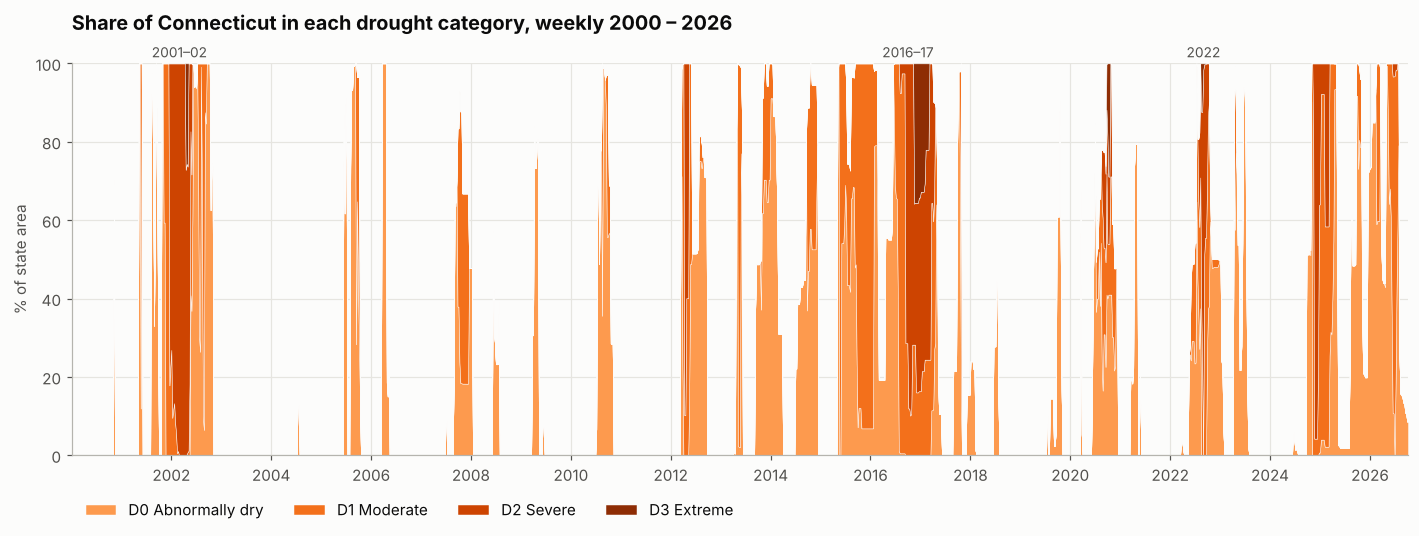

In [7]:
fig, ax = plt.subplots(figsize=(13, 5))
cats = ["D0", "D1", "D2", "D3"]
ax.stackplot(state.index, [state[f"{c}_only"] for c in cats],
             colors=[CAT_COLORS[c] for c in cats], labels=[CAT_LABELS[c] for c in cats],
             edgecolor="#fcfcfb", linewidth=0.3)
ax.set_ylim(0, 100)
ax.set_ylabel("% of state area")
ax.set_title("Share of Connecticut in each drought category, weekly 2000 – 2026", pad=22)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.margins(x=0)
ax.legend(loc="upper left", ncol=4, bbox_to_anchor=(0, -0.08))
for d, txt in [("2002-03-01", "2001–02"), ("2016-10-01", "2016–17"), ("2022-09-01", "2022")]:
    ax.annotate(txt, (pd.Timestamp(d), 100), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9, color="#52514e", annotation_clip=False)
plt.tight_layout()
plt.show()

**Takeaways:** Drought in Connecticut comes in distinct episodes, with long wet stretches in
between (2003–04, 2011, 2018–19, 2021). The worst were **2001–02**, **2015–17** and **2022**,
plus a severe spell in 2020; those are the only times any region reached **D3 (extreme)**. **D4 (exceptional)** never
happened.

## 5. Which years were driest?

In [8]:
yearly = state.groupby(state.index.year)[["D0", "D1", "D2", "D3"]].mean()
yearly.round(1)

,D0,D1,D2,D3
date,,,,
2000,1.4,0.0,0.0,0.0
2001,37.8,15.1,3.1,0.0
2002,81.0,48.6,36.8,1.5
2003,0.0,0.0,0.0,0.0
2004,0.5,0.0,0.0,0.0
2005,24.7,4.3,0.0,0.0
2006,10.8,0.0,0.0,0.0
2007,23.7,12.3,0.0,0.0
2008,6.1,0.0,0.0,0.0


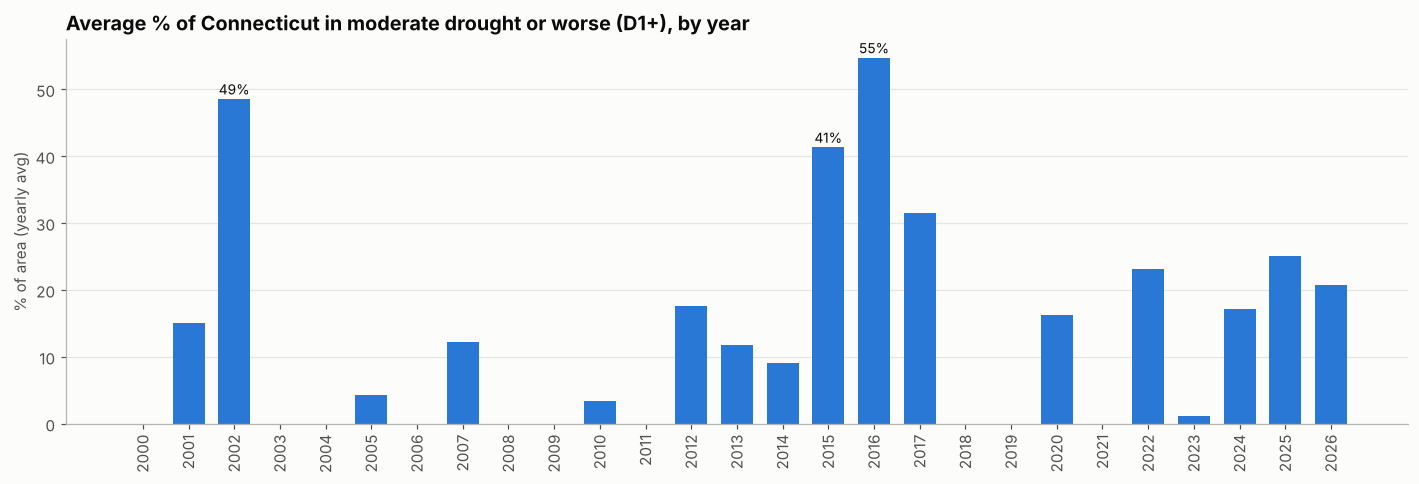

In [9]:
fig, ax = plt.subplots(figsize=(13, 4.5))
bars = ax.bar(yearly.index, yearly["D1"], color=BLUE, width=0.7)
ax.set_title("Average % of Connecticut in moderate drought or worse (D1+), by year")
ax.set_ylabel("% of area (yearly avg)")
ax.set_xticks(yearly.index)
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="x", visible=False)
# Label only the top 3 years
for yr in yearly["D1"].nlargest(3).index:
    v = yearly.loc[yr, "D1"]
    ax.annotate(f"{v:.0f}%", (yr, v), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=9, color="#0b0b0b")
plt.tight_layout()
plt.show()

## 6. Which regions are hit hardest? (region × year heatmap)

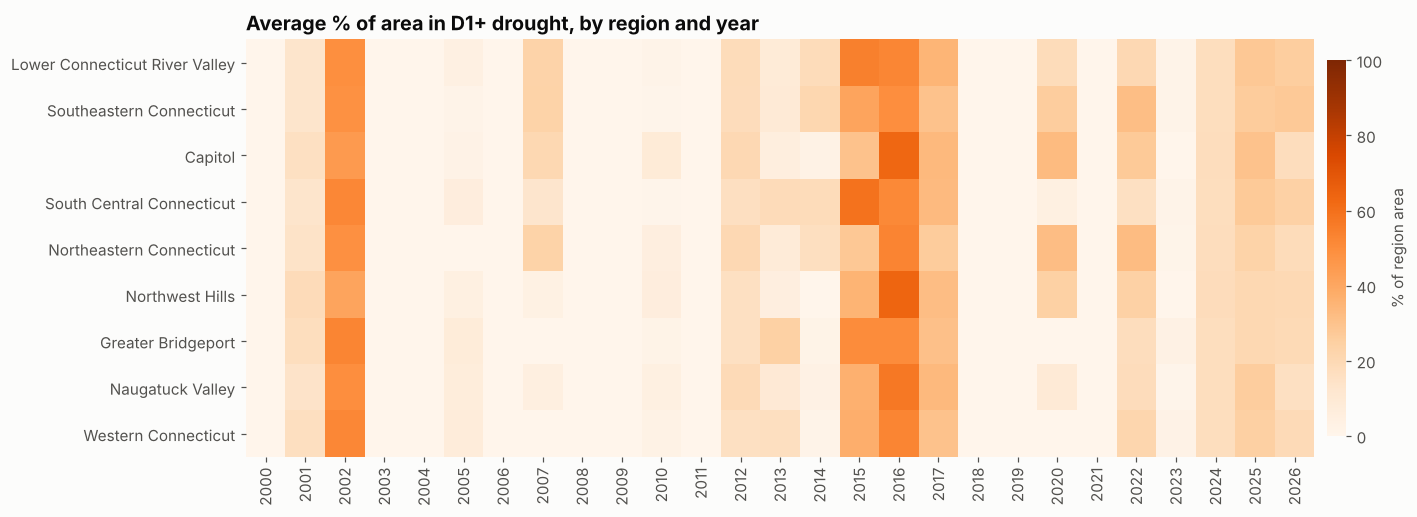

In [10]:
heat = df.pivot_table(index="region", columns="year", values="D1", aggfunc="mean")
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(14, 4.8))
im = ax.imshow(heat.values, aspect="auto", cmap="Oranges", vmin=0, vmax=100)
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=90)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Average % of area in D1+ drought, by region and year")
cb = fig.colorbar(im, ax=ax, pad=0.01, shrink=0.9)
cb.set_label("% of region area")
cb.outline.set_visible(False)
plt.tight_layout()
plt.show()

In [11]:
# Overall ranking: share of all weeks each region spent with any D1+ drought
rank = (df.assign(in_drought=df["D1"] > 0)
          .groupby("region")
          .agg(pct_weeks_D1plus=("in_drought", "mean"),
               avg_D1_area=("D1", "mean"),
               weeks_D2plus=("D2", lambda s: (s > 0).sum()),
               weeks_D3plus=("D3", lambda s: (s > 0).sum()))
          .sort_values("pct_weeks_D1plus", ascending=False))
rank["pct_weeks_D1plus"] = (rank["pct_weeks_D1plus"] * 100).round(1)
rank.round(1)

,pct_weeks_D1plus,avg_D1_area,weeks_D2plus,weeks_D3plus
region,,,,
Northeastern Connecticut,18.3,13.6,90,8
Capitol,18.1,13.7,104,20
Naugatuck Valley,18.0,12.0,90,19
Southeastern Connecticut,18.0,14.1,86,12
South Central Connecticut,17.8,13.6,81,15
Lower Connecticut River Valley,17.6,14.2,82,16
Western Connecticut,17.2,11.7,92,19
Northwest Hills,16.8,12.3,103,19
Greater Bridgeport,13.7,12.2,77,14


## 7. Seasonality: when in the year does drought happen?

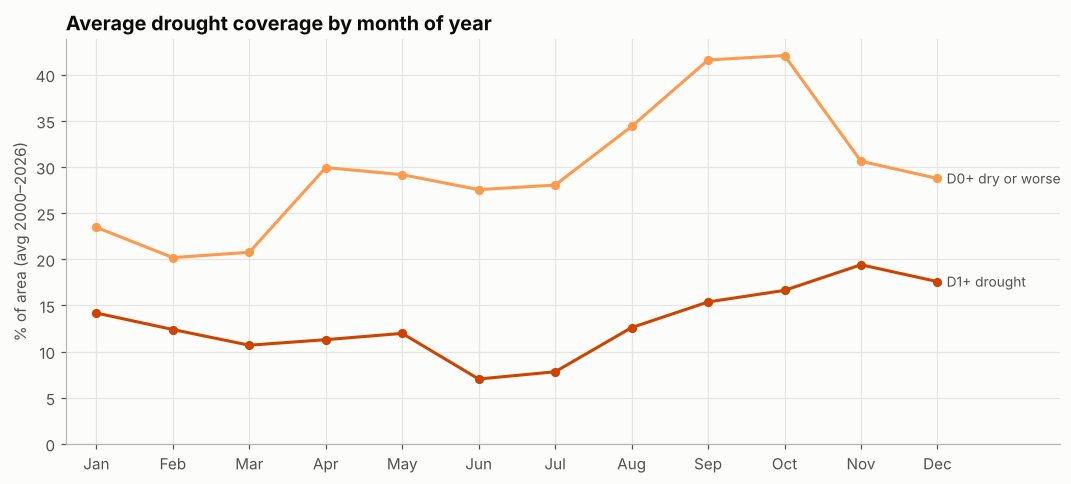

In [12]:
monthly = df.groupby("month")[["D0", "D1"]].mean()
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly.index, monthly["D0"], color=CAT_COLORS["D0"], lw=2, marker="o", ms=5)
ax.plot(monthly.index, monthly["D1"], color=CAT_COLORS["D2"], lw=2, marker="o", ms=5)
ax.set_xticks(range(1, 13), month_names)
ax.set_ylabel("% of area (avg 2000–2026)")
ax.set_ylim(0, None)
ax.set_title("Average drought coverage by month of year")
# direct labels on the right end
ax.annotate("D0+ dry or worse", (12, monthly.loc[12, "D0"]), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax.annotate("D1+ drought", (12, monthly.loc[12, "D1"]), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0.6, 13.6)
plt.tight_layout()
plt.show()

## 8. Drought episodes

An *episode* here is a run of consecutive weeks where some part of the state was in D1+ drought.

In [13]:
in_d = state["D1"] > 0
episode_id = (in_d != in_d.shift()).cumsum()
episodes = (state[in_d]
            .groupby(episode_id[in_d])
            .agg(start=("D1", lambda s: s.index.min().date()),
                 end=("D1", lambda s: s.index.max().date()),
                 weeks=("D1", "size"),
                 peak_D1_area=("D1", "max"),
                 peak_D2_area=("D2", "max"),
                 peak_D3_area=("D3", "max"))
            .sort_values("weeks", ascending=False)
            .reset_index(drop=True))
episodes.head(10).round(1)

,start,end,weeks,peak_D1_area,peak_D2_area,peak_D3_area
0,2016-06-21,2017-05-02,46,100.0,89.9,35.8
1,2015-05-19,2016-02-23,41,100.0,0.0,0.0
2,2022-05-24,2022-12-20,31,100.0,100.0,12.4
3,2001-11-06,2002-06-04,31,100.0,100.0,27.2
4,2024-10-22,2025-05-06,29,100.0,95.7,0.0
5,2020-06-23,2020-12-01,24,61.4,46.0,28.9
6,2026-04-21,2026-07-28,15,100.0,3.3,0.0
7,2013-10-22,2014-01-14,13,29.7,0.0,0.0
8,2007-09-25,2007-12-11,12,69.3,0.0,0.0
9,2014-09-23,2014-12-02,11,51.8,0.0,0.0


## 9. Recent conditions (2024 – 2026), by region

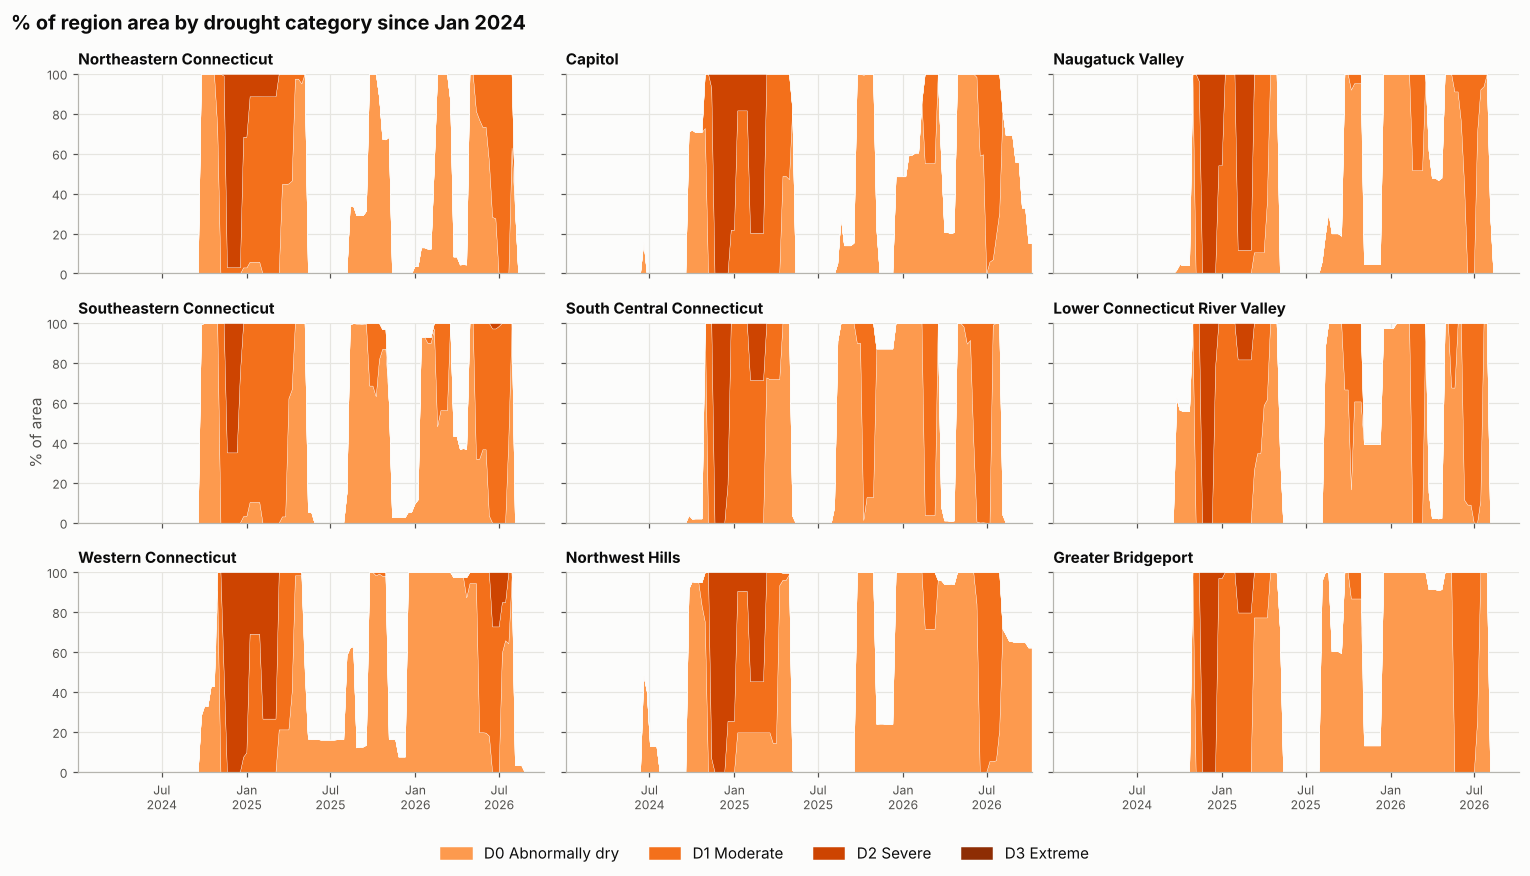

In [14]:
recent = df[df["date"] >= "2024-01-01"]
regions = rank.index  # most drought-prone first
fig, axes = plt.subplots(3, 3, figsize=(14, 8), sharex=True, sharey=True)
for ax, reg in zip(axes.flat, regions):
    r = recent[recent["region"] == reg].sort_values("date")
    ax.stackplot(r["date"], [r[f"{c}_only"] for c in cats],
                 colors=[CAT_COLORS[c] for c in cats], edgecolor="#fcfcfb", linewidth=0.2)
    ax.set_title(reg, fontsize=10)
    ax.set_ylim(0, 100)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.tick_params(labelsize=8)
    ax.margins(x=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=CAT_COLORS[c]) for c in cats]
fig.legend(handles, [CAT_LABELS[c] for c in cats], loc="lower center", ncol=4)
fig.suptitle("% of region area by drought category since Jan 2024", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.supylabel("% of area", fontsize=10, color="#52514e")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

In [15]:
latest = df[df["date"] == df["date"].max()]
print("Latest map:", df["date"].max().date())
latest[["region", "None", "D0", "D1", "D2", "D3"]].sort_values("D0", ascending=False).reset_index(drop=True)

Latest map: 2026-10-06


,region,None,D0,D1,D2,D3
0,Northwest Hills,37.76,62.24,0.0,0.0,0.0
1,Capitol,84.71,15.29,0.0,0.0,0.0
2,Greater Bridgeport,100.00,0.00,0.0,0.0,0.0
3,Naugatuck Valley,100.00,0.00,0.0,0.0,0.0
4,Lower Connecticut River Valley,100.00,0.00,0.0,0.0,0.0
5,Northeastern Connecticut,100.00,0.00,0.0,0.0,0.0
6,South Central Connecticut,100.00,0.00,0.0,0.0,0.0
7,Southeastern Connecticut,100.00,0.00,0.0,0.0,0.0
8,Western Connecticut,100.00,0.00,0.0,0.0,0.0


## 10. Summary

* **27 years of weekly data, 9 regions, no missing values.** The only cleanup needed was parsing
  dates and turning the cumulative D-columns into exclusive ones.
* **The big drought episodes were 2001–02, 2015–17 and 2022.** The longest unbroken run of
  D1+ drought was Jun 2016 – May 2017 (46 weeks). Late 2024 – spring 2025 was also severe (D2 over ~96 % of the state).
* **Extreme drought (D3) is rare** (only in 2002, 2016–17, 2020 and 2022), and exceptional
  drought (D4) never happened.
* **Seasonality:** drought coverage is lowest in June, builds through late summer
  (abnormally dry peaks Sep–Oct), and D1+ drought peaks in November before winter and spring
  usually clear it.
* **2025–26:** much of the state was abnormally dry for most of 2026, but by the latest map
  (Oct 6, 2026) only the Northwest Hills and Capitol regions were still abnormally dry, with
  no D1+ drought anywhere.

### Ideas to explore next
* Weight the statewide average by region land area for an exact statewide number.
* Join precipitation/temperature data (e.g. NOAA) to explain the episodes.
* Make an interactive version with `plotly` (`px.area(...)`) to hover over individual weeks.